In [1]:
# 1. Mengimpor Library
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import os

In [2]:
# 2. Mengimpor Dataset
dataset_path = 'Posisi_gaji.csv' if os.path.exists('Posisi_gaji.csv') else ('Jobsheet6_Regresi/Posisi_gaji.csv' if os.path.exists('Jobsheet6_Regresi/Posisi_gaji.csv') else 'Posisi_gaji.csv')
dataset = pd.read_csv(dataset_path)

X = dataset.iloc[:, 1:2].values  # Kolom Level
y = dataset.iloc[:, 2].values    # Kolom Gaji
print("Data awal Posisi & Gaji:")
display(dataset)

Data awal Posisi & Gaji:


,Posisi,Level,Gaji
0,Business Analyst,1,45000
1,Junior Consultant,2,50000
2,Senior Consultant,3,60000
3,Manager,4,80000
4,Country Manager,5,110000
5,Region Manager,6,150000
6,Partner,7,200000
7,Senior Partner,8,300000
8,C-level,9,500000
9,CEO,10,1000000


In [3]:
# 3. Feature Scaling
# StandardScaler diperlukan karena SVR sangat sensitif terhadap perbedaan skala fitur
sc_X = StandardScaler()
sc_y = StandardScaler()
X_scaled = sc_X.fit_transform(X.reshape(-1, 1))
y_scaled = sc_y.fit_transform(y.reshape(-1, 1))

In [4]:
# 4. Fitting SVR ke Dataset
regressor = SVR(kernel='rbf')
regressor.fit(X_scaled, y_scaled.ravel())
print("Model SVR dengan kernel RBF berhasil dilatih!")

Model SVR dengan kernel RBF berhasil dilatih!


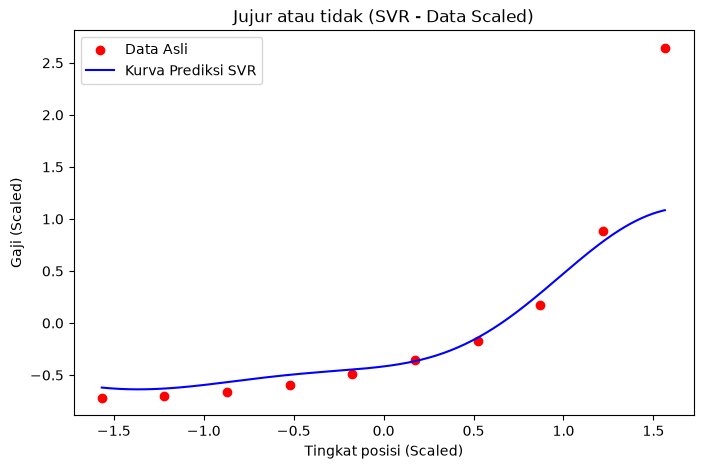

In [5]:
# 5. Visualisasi Hasil SVR
X_grid = np.arange(X_scaled.min(), X_scaled.max(), 0.01).reshape(-1, 1)
plt.figure(figsize=(8, 5))
plt.scatter(X_scaled, y_scaled, color='red', label='Data Asli')
plt.plot(X_grid, regressor.predict(X_grid), color='blue', label='Kurva Prediksi SVR')
plt.title('Jujur atau tidak (SVR - Data Scaled)')
plt.xlabel('Tingkat posisi (Scaled)')
plt.ylabel('Gaji (Scaled)')
plt.legend()
plt.show()

In [6]:
# 6 & 7. Prediksi Hasil untuk Tingkat Posisi 6.5
# Buat array 2D yang berisi tingkat posisi 6.5
tingkat_posisi_prediksi = np.array([[6.5]])
# Penskalaan fitur
tingkat_posisi_prediksi_scaled = sc_X.transform(tingkat_posisi_prediksi)
# Prediksi menggunakan model SVR
gaji_prediksi_scaled = regressor.predict(tingkat_posisi_prediksi_scaled)
# Kembalikan hasil prediksi ke skala aslinya
gaji_prediksi = sc_y.inverse_transform(gaji_prediksi_scaled.reshape(-1, 1))

print("Prediksi Gaji untuk Tingkat Posisi 6.5:", gaji_prediksi[0][0])

Prediksi Gaji untuk Tingkat Posisi 6.5: 170370.02040650236


In [7]:
# 9. Evaluasi Model SVR
y_actual = y_scaled.ravel()
y_pred = regressor.predict(X_scaled)

mae = mean_absolute_error(y_actual, y_pred)
mse = mean_squared_error(y_actual, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_actual, y_pred)

print("=== Hasil Evaluasi Model SVR ===")
print("MAE      :", mae)
print("MSE      :", mse)
print("RMSE     :", rmse)
print("R-squared:", r2)

=== Hasil Evaluasi Model SVR ===
MAE      : 0.22299274095734414
MSE      : 0.24839989293792014
RMSE     : 0.4983973243687411
R-squared: 0.7516001070620798
